In [28]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [3]:
data = pd.read_csv('creditcard.csv')

In [4]:
data.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [5]:
x = data.drop("Class",axis=1)
y = data["Class"]

In [7]:
x_normal = x[y==0]
x_abnormal = x[y==1]

In [8]:
x_train,x_test_normal = train_test_split(
    x_normal,
    test_size=42,
    random_state = 42
)

In [9]:
x_test = pd.concat([x_test_normal,x_abnormal])
y_test = np.concatenate([
    np.zeros(len(x_test_normal)),
    np.ones(len(x_abnormal))
])
            
             

In [10]:
scaler = StandardScaler()

x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [11]:
n = x_train.shape[1]
model = Sequential()

In [12]:
model.add(Dense(32, activation='relu', input_shape=(n,)))
model.add(Dense(16, activation='relu'))
model.add(Dense(8, activation='relu'))

/opt/anaconda3/lib/python3.13/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [14]:
model.add(Dense(16,activation = 'relu'))
model.add(Dense(32,activation = 'relu'))
model.add(Dense(n,activation = 'linear'))

In [15]:
model.compile(
    optimizer = 'adam',
    loss = 'mse',
    metrics = ['mae']
)

In [16]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 30)             │           990 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 30)             │           990 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,364 (20.95 KB)

 Trainable params: 5,364 (20.95 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
model.fit(
    x_train,x_train,
    epochs = 30,
    batch_size = 32,
    validation_split = 0.2
)

Epoch 1/30
7107/7107 ━━━━━━━━━━━━━━━━━━━━ 3s 356us/step - loss: 0.5307 - mae: 0.4942 - val_loss: 0.3853 - val_mae: 0.4266
Epoch 2/30
7107/7107 ━━━━━━━━━━━━━━━━━━━━ 3s 363us/step - loss: 0.3555 - mae: 0.4067 - val_loss: 0.3421 - val_mae: 0.4016
Epoch 3/30
7107/7107 ━━━━━━━━━━━━━━━━━━━━ 2s 347us/step - loss: 0.3157 - mae: 0.3796 - val_loss: 0.3007 - val_mae: 0.3665
Epoch 4/30
7107/7107 ━━━━━━━━━━━━━━━━━━━━ 3s 354us/step - loss: 0.2951 - mae: 0.3649 - val_loss: 0.2832 - val_mae: 0.3538
Epoch 5/30
7107/7107 ━━━━━━━━━━━━━━━━━━━━ 2s 345us/step - loss: 0.2832 - mae: 0.3560 - val_loss: 0.2939 - val_mae: 0.3565
Epoch 6/30
7107/7107 ━━━━━━━━━━━━━━━━━━━━ 2s 340us/step - loss: 0.2666 - mae: 0.3453 - val_loss: 0.2580 - val_mae: 0.3362
Epoch 7/30
7107/7107 ━━━━━━━━━━━━━━━━━━━━ 2s 349us/step - loss: 0.2574 - mae: 0.3381 - val_loss: 0.2492 - val_mae: 0.3306
Epoch 8/30
7107/7107 ━━━━━━━━━━━━━━━━━━━━ 2s 348us/step - loss: 0.2501 - mae: 0.3330 - val_loss: 0.2485 - val_mae: 0.3349
Epoch 9/30
7107/7107 ━━━

In [18]:
reconstructed = model.predict(x_test)

17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


In [19]:
error = np.mean(
    np.square(x_test - reconstructed),
    axis = 1
)

In [20]:
print(error)

[3.50878689e-02 5.30639660e-02 1.87238894e-01 7.36611409e-02
 1.84748186e-01 1.42060828e-02 2.57741409e-01 3.30002616e-02
 1.73121521e-01 8.76805277e-02 3.49800965e-02 1.06778495e-01
 2.83176036e-02 4.20359947e-02 3.12965552e-02 1.55704810e-01
 9.75919451e-02 1.57162429e-01 2.24745650e-02 1.53429572e-02
 1.29459785e-01 7.63033179e-02 1.26184641e-01 6.00596498e-02
 3.60186779e-01 2.82086587e-01 1.79313235e-01 5.09016549e-02
 2.05062426e-01 5.03586231e-02 2.48385098e-02 1.18865418e-01
 1.20514430e-01 1.47885731e-01 4.63605600e-02 3.16630963e-01
 4.95737481e-02 1.69474029e-01 5.76373112e-02 4.25422000e-02
 7.88391445e-02 3.39965063e-02 3.10493789e+00 1.12976442e+00
 3.43751719e+00 2.11620263e+01 8.01834942e+00 1.42456653e+01
 1.38592310e+01 1.15185058e+01 1.07174776e+01 9.21004125e+00
 9.43467817e+00 6.09176445e+00 8.62143295e+00 8.68478453e+00
 1.00554747e+01 1.70999969e+01 1.71504391e+01 1.29807153e+01
 1.27972365e+01 1.21039986e+01 1.21244413e+01 1.98248696e+01
 1.62354688e+01 1.627953

In [21]:
train_reconstructed = model.predict(x_train)
train_error = np.mean(
    np.square(x_train - train_reconstructed),
    axis = 1
)

8884/8884 ━━━━━━━━━━━━━━━━━━━━ 1s 147us/step


In [22]:
threshold = np.percentile(train_error,95)

In [23]:
print("Threshold = ",threshold)

Threshold =  0.5815054982708198


In [24]:
predictions = (error > threshold).astype(int)
for i in range(10):
    if predictions[i] == 1:
        print("Abnormal")
    else:
        print("Normal")
        

Normal
Normal
Normal
Normal
Normal
Normal
Normal
Normal
Normal
Normal


In [26]:
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

         0.0       0.40      1.00      0.57        42
         1.0       1.00      0.87      0.93       492

    accuracy                           0.88       534
   macro avg       0.70      0.93      0.75       534
weighted avg       0.95      0.88      0.90       534



In [29]:
print("Accuracy:", accuracy_score(y_test, predictions))

print("Precision:", precision_score(y_test, predictions))

print("Recall:", recall_score(y_test, predictions))

print("F1 Score:", f1_score(y_test, predictions))

Accuracy: 0.8801498127340824
Precision: 1.0
Recall: 0.8699186991869918
F1 Score: 0.9304347826086956


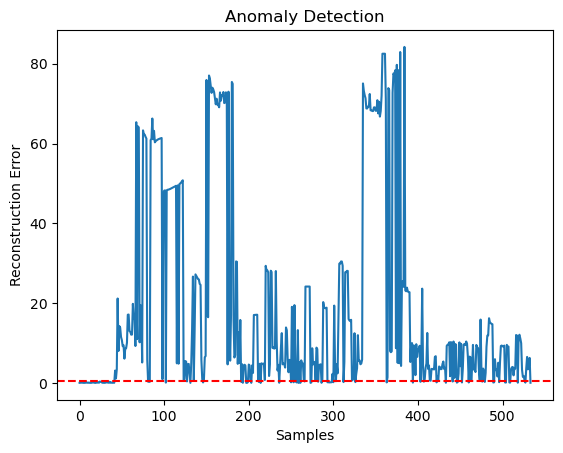

In [30]:
plt.plot(error)
plt.axhline(threshold, color='red', linestyle='--')

plt.title("Anomaly Detection")
plt.xlabel("Samples")
plt.ylabel("Reconstruction Error")
plt.show()


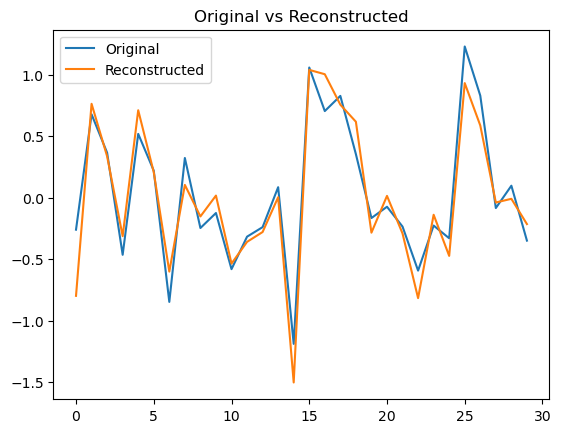

In [32]:
plt.plot(x_test[0], label="Original")
plt.plot(reconstructed[0], label="Reconstructed")

plt.title("Original vs Reconstructed")
plt.legend()
plt.show()